In [33]:
from datasets import load_dataset
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter
import pandas as pd

In [34]:
ds_full = load_dataset("Artificio/WikiArt_Full", split="train", cache_dir="data")

In [35]:
print(ds_full)                # features + num_rows
print(len(ds_full))           # 103250
print(ds_full.column_names)
print(ds_full.features)       # types per column
print(ds_full.info.description)

Dataset({
    features: ['title', 'artist', 'date', 'genre', 'style', 'description', 'filename', 'image', 'embeddings_pca512', 'resnet50_non_robust_feats', 'resnet50_robust_feats'],
    num_rows: 103250
})
103250
['title', 'artist', 'date', 'genre', 'style', 'description', 'filename', 'image', 'embeddings_pca512', 'resnet50_non_robust_feats', 'resnet50_robust_feats']
{'title': Value('string'), 'artist': Value('string'), 'date': Value('string'), 'genre': Value('string'), 'style': Value('string'), 'description': Value('string'), 'filename': Value('string'), 'image': Image(mode=None, decode=True), 'embeddings_pca512': List(Value('float32')), 'resnet50_non_robust_feats': List(Value('float32')), 'resnet50_robust_feats': List(Value('float32'))}



In [36]:
print(ds_full.info)

DatasetInfo(features={'title': Value('string'), 'artist': Value('string'), 'date': Value('string'), 'genre': Value('string'), 'style': Value('string'), 'description': Value('string'), 'filename': Value('string'), 'image': Image(mode=None, decode=True), 'embeddings_pca512': List(Value('float32')), 'resnet50_non_robust_feats': List(Value('float32')), 'resnet50_robust_feats': List(Value('float32'))}, builder_name='parquet', dataset_name='wiki_art_full', config_name='default', version=0.0.0, splits={'train': SplitInfo(name='train', num_bytes=3411668192, num_examples=103250, shard_lengths=[15750, 15750, 15750, 15750, 15750, 15750, 8750], dataset_name='wiki_art_full')}, download_size=3245866583, dataset_size=3411668192, size_in_bytes=6657534775)


Column([<PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=256x256 at 0x1B5900D4B30>, <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=256x256 at 0x1B5900D4D10>, <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=256x256 at 0x1B5900D6510>, <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=256x256 at 0x1B5900D7350>, <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=256x256 at 0x1B5900D55E0>, ...])


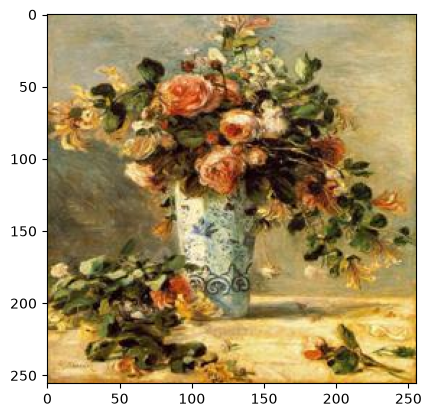

In [37]:
print(ds_full['image'])
plt.imshow(ds_full['image'][79082])

In [38]:
styles = ds_full.unique("style")
print(len(styles))
Counter(ds_full['style'])

137


Counter({'Impressionism': 10643,
         'Realism': 10523,
         'Romanticism': 9285,
         'Expressionism': 7013,
         'Post-Impressionism': 5778,
         'Art Nouveau (Modern)': 4899,
         'Baroque': 4400,
         'Surrealism': 4167,
         'Symbolism': 3476,
         'Rococo': 2733,
         'Northern Renaissance': 2379,
         'Naïve Art (Primitivism)': 2295,
         'Abstract Expressionism': 2074,
         'Neoclassicism': 2038,
         'Cubism': 1747,
         'Ukiyo-e': 1426,
         'Early Renaissance': 1351,
         'Mannerism (Late Renaissance)': 1342,
         'High Renaissance': 1314,
         'Art Informel': 1267,
         'Magic Realism': 1002,
         'None': 986,
         'Abstract Art': 979,
         'Academicism': 972,
         'Color Field Painting': 910,
         'Pop Art': 791,
         'Fauvism': 731,
         'Lyrical Abstraction': 670,
         'Art Deco': 644,
         'Concretism': 581,
         'Neo-Romanticism': 566,
         'Ink a

count      137.000000
mean       753.649635
std       1794.764037
min          1.000000
25%         36.000000
50%        137.000000
75%        460.000000
max      10643.000000
dtype: float64
Styles with fewer than 50 examples: 45


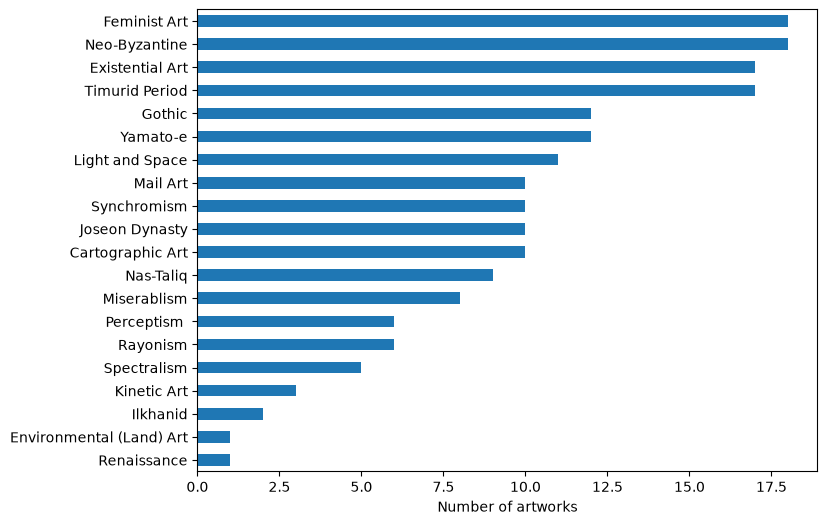

In [42]:
counts = pd.Series(Counter(ds_full["style"])).sort_values(ascending=False)
print(counts.describe())
print("Styles with fewer than 50 examples:", (counts < 50).sum())

counts.tail(20).sort_values().plot.barh(figsize=(8, 6))
plt.xlabel("Number of artworks")
plt.show()